In [ ]:
%pip -q install -q torch-geometric

In [ ]:
# ---- Configuración de Advertencias ----
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="torch.jit")

# ---- Bibliotecas de Ciencia de Datos y Visualización ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LinearSegmentedColormap

# ---- Análisis y Modelado de Grafos ----
import networkx as nx

# ---- PyTorch (Deep Learning General) ----
import torch
import torch.nn.functional as F

# ---- PyTorch Geometric (Deep Learning en Grafos) ----
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_dense_adj

# === Funciones auxiliares ===
from IPython.display import HTML, display, Markdown, Math
from tabulate import tabulate

def dMarkdown(text):
    """
    Muestra texto enriquecido en formato Markdown en el notebook.
    Parámetros:
    text (str): Cadena de caracteres formateada en Markdown.
    """
    display(Markdown(text))

def dM_table(datos_tabla, headers):
    """
    Toma una lista de datos y cabeceras, y muestra una tabla formateada en Markdown.
    Parámetros:
    datos_tabla (list of lists): Filas con la información a mostrar.
    headers (list of str): Nombres de las columnas de la tabla.
    """
    tabla_md = tabulate(
        datos_tabla,
        headers=headers,
        tablefmt="pipe"
    )
    dMarkdown(tabla_md)

def dMath(text):
    """
    Muestra texto enriquecido en formato LaTeX en el notebook.
    Parámetros:
    text (str): Cadena de caracteres formateada en LaTeX.
    """
    display(Math(text))

def numpy_to_latex_matrix(arr, fmt="{:g}"):
    """
    Converts a NumPy array into a LaTeX bmatrix string.
    """
    if arr.ndim == 1:
        arr = arr[np.newaxis, :]

    lines = []
    for row in arr:
        # Format each element and join with '&'
        lines.append(" & ".join([fmt.format(x) for x in row]))

    # Join rows with '\\' and wrap in bmatrix environment
    latex_str = "\\begin{bmatrix}\n" + " \\\\\n".join(lines) + "\n\\end{bmatrix}"
    return latex_str

* https://x.com/Vslowsprinter/status/1437246695469772802
* https://x.com/Vslowsprinter/status/2113419232658833417

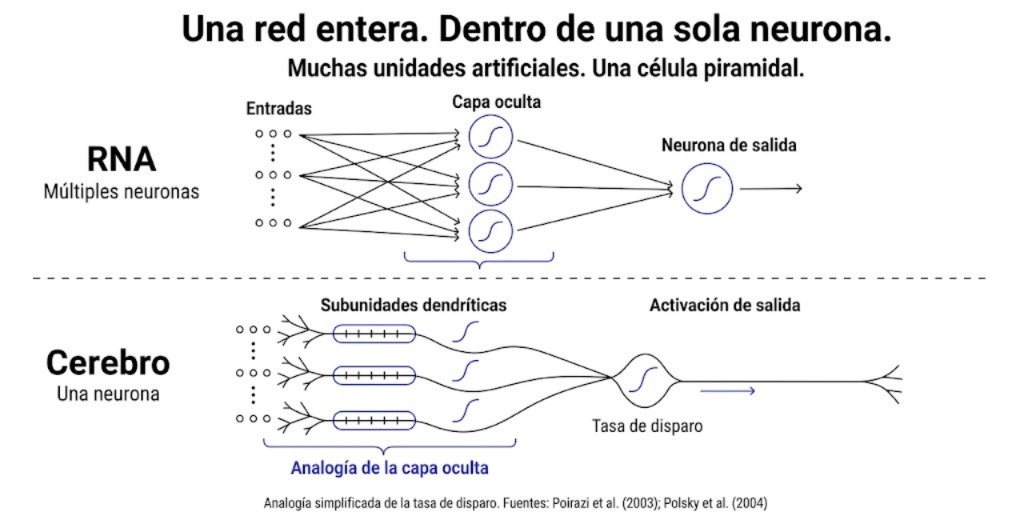

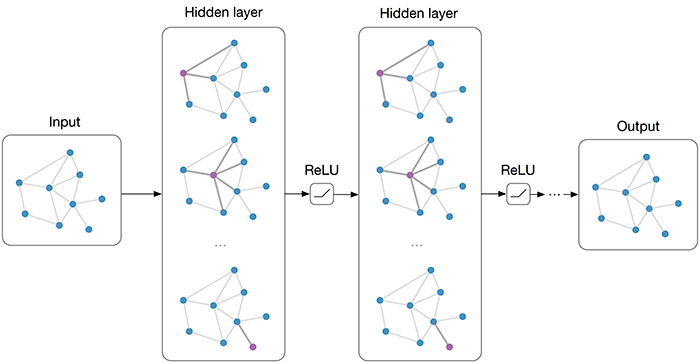

La imagen muestra la arquitectura de una **Red Convolucional de Grafos (GCN, *Graph Convolutional Network*)**, la cual se representa matricialmente en dos niveles: la topología del grafo base de 9 nodos y las ecuaciones matriciales de propagación a través de las capas ocultas (*Hidden layers*) con funciones de activación $\text{ReLU}$.

**1. Numeración de los nodos del grafo**

Para construir las matrices del grafo de $N = 9$ nodos y $13$ aristas que se repite en cada bloque, asignamos los índices del $1$ al $9$ según su posición visual:

* **Nodo 1:** Arriba a la izquierda (resaltado en morado en el primer subgrafo de las capas ocultas).


* **Nodo 2:** Nodo central (resaltado en morado en el segundo subgrafo de las capas ocultas).


* **Nodo 3:** Abajo a la izquierda.


* **Nodo 4:** Extremo superior.


* **Nodo 5:** Derecha media-alta.


* **Nodo 6:** Abajo al centro.


* **Nodo 7:** Nodo ramificador inferior derecho.


* **Nodo 8:** Extremo derecho (nodo hoja superior).


* **Nodo 9:** Extremo inferior derecho (nodo hoja resaltado en morado en el tercer subgrafo).



**2. Matrices topológicas del grafo ($A$, $D$ y $X$)**

**Matriz de Adyacencia ($A \in \{0,1\}^{9 \times 9}$)**
Indica con un $1$ si existe una arista entre el nodo $i$ y el nodo $j$, y con un $0$ en caso contrario:

$$A = \begin{pmatrix} 0 & 1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\ 1 & 0 & 0 & 1 & 1 & 1 & 1 & 0 & 0 \\ 1 & 0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 \\ 1 & 1 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\ 0 & 1 & 0 & 1 & 0 & 0 & 1 & 0 & 0 \\ 0 & 1 & 1 & 0 & 0 & 0 & 1 & 0 & 0 \\ 0 & 1 & 0 & 0 & 1 & 1 & 0 & 1 & 1 \\ 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 \end{pmatrix}$$

**Matriz de Grados ($D \in \mathbb{R}^{9 \times 9}$)**
Es una matriz diagonal donde cada elemento $D_{ii} = \sum_j A_{ij}$ representa el número de conexiones de cada nodo:

$$D = \text{diag}(3, 5, 2, 3, 3, 3, 5, 1, 1)$$

**Matriz de Características de Entrada ($X \in \mathbb{R}^{9 \times F_0}$)**
En el bloque **Input**, cada nodo $i$ posee un vector de atributos de dimensión $F_0$, formando la matriz de entrada $H^{(0)} = X$.

**3. Representación matricial de la red neuronal (Capas Ocultas y Salida)**

En cada **Hidden layer**, cada nodo (ilustrado en morado desde el nodo $1$ hasta el nodo $9$) agrega la información de sus vecinos directos (aristas resaltadas en gris grueso) y de sí mismo.

* **Adyacencia con auto-conexiones (*self-loops*):** Se suma la matriz identidad $I_9$ para que cada nodo conserve su propia información al actualizarse:

$$\tilde{A} = A + I_9, \quad \tilde{D} = D + I_9 = \text{diag}(4, 6, 3, 4, 4, 4, 6, 2, 2)$$


* **Matriz de propagación normalizada ($\hat{A} \in \mathbb{R}^{9 \times 9}$):** Para evitar que los nodos altamente conectados (como los nodos $2$ y $7$) dominen las sumas, se aplica normalización simétrica:

$$\hat{A} = \tilde{D}^{-\frac{1}{2}} \tilde{A} \tilde{D}^{-\frac{1}{2}}$$


* **Primera capa oculta + ReLU:** Multiplica la estructura normalizada del grafo $\hat{A}$ por los atributos de entrada $X$ y por la matriz de pesos entrenables $W^{(0)} \in \mathbb{R}^{F_0 \times F_1}$, aplicando luego la función $\text{ReLU}(z) = \max(0, z)$ elemento a elemento:



$$H^{(1)} = \text{ReLU}\left( \hat{A} X W^{(0)} \right)$$


* **Segunda capa oculta + ReLU:** Toma las representaciones $H^{(1)}$ de la primera capa y vuelve a agregar la vecindad mediante la matriz de pesos $W^{(1)} \in \mathbb{R}^{F_1 \times F_2}$:



$$H^{(2)} = \text{ReLU}\left( \hat{A} H^{(1)} W^{(1)} \right)$$


*  Expresión matricial compacta de extremo a extremo (Input $\rightarrow$ Output): Si la red consta de las dos capas ocultas mostradas seguidas de una proyección de salida con pesos $W^{(out)} \in \mathbb{R}^{F_2 \times F_{out}}$, el bloque **Output** ($Y \in \mathbb{R}^{9 \times F_{out}}$) se expresa como:



$$Y = \sigma\left( \hat{A} \, \text{ReLU}\left( \hat{A} \, \text{ReLU}\left( \hat{A} X W^{(0)} \right) W^{(1)} \right) W^{(out)} \right)$$



donde $\sigma(\cdot)$ corresponde a la función de salida final (por ejemplo, la identidad para regresión en nodos o $\text{softmax}$ por filas para clasificación de nodos).

Para representar tanto las matrices topológicas del grafo de 9 nodos como el paso hacia adelante (forward pass) a través de las dos capas ocultas (Hidden layers) con activación $\text{ReLU}$ y la capa de salida (Output), puedes utilizar NetworkX y NumPy (para el álgebra matricial explícita) o PyTorch Geometric (el estándar para redes neuronales de grafos).

1. Álgebra matricial explícita con NetworkX y NumPyEste bloque construye el grafo exacto de 9 nodos y 13 aristas de la imagen (indexados de 0 a 8), extrae las matrices $A$, $D$ y $\hat{A}$, y calcula las transformaciones matriciales de cada capa:   

In [ ]:
# 1. Definir la topología del grafo (9 nodos indexados de 0 a 8)
G = nx.Graph()
G.add_nodes_from(range(9))

aristas = [
    (0, 1), (0, 2), (0, 3),          # Conexiones del nodo 1 (índice 0)
    (1, 3), (1, 4), (1, 5), (1, 6),  # Conexiones adicionales del nodo central (índice 1)
    (2, 5),                          # Conexión inferior izquierda
    (3, 4),                          # Conexión superior derecha
    (4, 6), (5, 6),                  # Conexiones hacia el nodo ramificador (índice 6)
    (6, 7), (6, 8)                   # Nodos hoja a la derecha (índices 7 y 8)
]
G.add_edges_from(aristas)

# 2. Obtener Matriz de Adyacencia (A) y Matriz de Grados (D)
A = nx.to_numpy_array(G, nodelist=range(9), dtype=int)
grados = np.sum(A, axis=1)
D = np.diag(grados)

# Mostrar Matriz A usando dM_table para mejor visualización
dMarkdown("### Matriz de Adyacencia ($A$)")
dM_table(A.tolist(), headers=[f"N{i+1}" for i in range(9)])

dMath("A = " + numpy_to_latex_matrix(A))

dMarkdown(f"**Grados de cada nodo (diagonal de $D$):** {grados.tolist()}")

# 3. Normalización simétrica con auto-conexiones (A_hat = D_tilde^(-1/2) * A_tilde * D_tilde^(-1/2))
I = np.eye(9)
A_tilde = A + I
D_tilde_inv_sqrt = np.diag(1.0 / np.sqrt(np.sum(A_tilde, axis=1)))
A_hat = D_tilde_inv_sqrt @ A_tilde @ D_tilde_inv_sqrt

# 4. Simulación de las capas de la red (Input -> Hidden 1 -> ReLU -> Hidden 2 -> ReLU -> Output)
np.random.seed(42)
F_in, F_h1, F_h2, F_out = 4, 8, 8, 2  # Dimensiones de características por capa

X = np.random.randn(9, F_in)          # Bloque Input (9 x F_in)
W0 = np.random.randn(F_in, F_h1)      # Pesos Hidden layer 1
W1 = np.random.randn(F_h1, F_h2)      # Pesos Hidden layer 2
W_out = np.random.randn(F_h2, F_out)  # Pesos Output

relu = lambda z: np.maximum(0, z)

# Propagación matricial según el diagrama
H1 = relu(A_hat @ X @ W0)             # Salida de la 1ª Hidden layer + ReLU
H2 = relu(A_hat @ H1 @ W1)            # Salida de la 2ª Hidden layer + ReLU
Output = A_hat @ H2 @ W_out           # Bloque Output

dMarkdown("### Dimensiones de las Capas")
display_data = [
    ["Input (X)", str(X.shape)],
    ["Hidden Layer 1 (H1)", str(H1.shape)],
    ["Hidden Layer 2 (H2)", str(H2.shape)],
    ["Output (Y)", str(Output.shape)]
]
dM_table(display_data, headers=["Capa", "Dimensión (Nodos x Atributos)"])

2. Representación en Deep Learning con PyTorch y PyTorch GeometricEn librerías especializadas como PyTorch Geometric (`torch_geometric`), la matriz de adyacencia se almacena en formato disperso COO (`edge_index`, una matriz de dimensión $2 \times 26$ para las $13$ aristas bidireccionales) y las capas GCNConv calculan internamente $\hat{A} H^{(l)} W^{(l)}$:

In [ ]:
# Representación dispersa de la matriz de adyacencia (edge_index)
aristas_origen  = [0, 0, 0, 1, 1, 1, 1, 2, 3, 4, 5, 6, 6]
aristas_destino = [1, 2, 3, 3, 4, 5, 6, 5, 4, 6, 6, 7, 8]

# Hacemos el grafo no dirigido duplicando las direcciones
edge_index = torch.tensor([
    aristas_origen + aristas_destino,
    aristas_destino + aristas_origen
], dtype=torch.long)

# Convertir a la matriz de adyacencia densa (9x9) para verificar
A_torch = to_dense_adj(edge_index)[0]

# Matriz de características de entrada (Input: 9 nodos con 4 atributos cada uno)
X = torch.randn((9, 4), dtype=torch.float)
grafo = Data(x=X, edge_index=edge_index)

# 2. Definir la arquitectura mostrada en el diagrama
class RedGrafoGCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.hidden1 = GCNConv(in_channels, hidden_channels)
        self.hidden2 = GCNConv(hidden_channels, hidden_channels)
        self.out_layer = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        # Primera Hidden layer + ReLU
        h = self.hidden1(x, edge_index)
        h = F.relu(h)

        # Segunda Hidden layer + ReLU
        h = self.hidden2(h, edge_index)
        h = F.relu(h)

        # Capa de salida (Output)
        out = self.out_layer(h, edge_index)
        return out

# 3. Instanciar y ejecutar el modelo
modelo = RedGrafoGCN(in_channels=4, hidden_channels=8, out_channels=2)
salida = modelo(grafo.x, grafo.edge_index)

dMarkdown(f"**Matriz de salida (Output) de dimensión [Nodos, Características]:** `{list(salida.shape)}`")

Para replicar exactamente la disposición espacial de la imagen, debemos fijar manualmente las coordenadas $(x, y)$ de los 9 nodos mediante un diccionario de posiciones en NetworkX.El siguiente código dibuja tanto el grafo base (Input / Output) como las tres variaciones de las capas ocultas (Hidden layers), donde se resalta en morado el nodo objetivo y en gris grueso las aristas de su vecindario inmediato:

In [ ]:
# Crear el grafo y sus 13 aristas (nodos indexados de 0 a 8)
G = nx.Graph()
G.add_nodes_from(range(9))

aristas = [
    (0, 1), (0, 2), (0, 3),          # Vecinos del nodo 0 (arriba-izquierda)
    (1, 3), (1, 4), (1, 5), (1, 6),  # Vecinos adicionales del nodo 1 (central)
    (2, 5),                          # Arista inferior izquierda
    (3, 4),                          # Arista superior derecha
    (4, 6), (5, 6),                  # Conexiones hacia el nodo 6 (ramificador)
    (6, 7), (6, 8)                   # Nodos hoja a la derecha (7 y 8)
]
G.add_edges_from(aristas)

# 2. Coordenadas exactas (x, y) para replicar la disposición visual de la imagen
pos = {
    0: (0.15, 0.55),  # Arriba a la izquierda
    1: (0.42, 0.48),  # Nodo central
    2: (0.20, 0.25),  # Abajo a la izquierda
    3: (0.62, 0.88),  # Extremo superior
    4: (0.70, 0.65),  # Derecha media-alta
    5: (0.52, 0.15),  # Abajo al centro
    6: (0.65, 0.36),  # Nodo ramificador inferior derecho
    7: (0.90, 0.42),  # Extremo derecho (hoja superior)
    8: (0.80, 0.12)   # Extremo inferior derecho (hoja inferior)
}

# 3. Función auxiliar para graficar el estado del grafo y resaltar un nodo
def dibujar_subgrafo(ax, titulo, nodo_destacado=None):
    # Colores de los nodos: azul por defecto, morado para el nodo activo
    colores_nodos = [
        "#88419d" if n == nodo_destacado else "#1f77b4"
        for n in G.nodes()
    ]

    # Separar aristas normales de las aristas conectadas al nodo destacado
    aristas_destacadas = []
    if nodo_destacado is not None:
        aristas_destacadas = [
            e for e in G.edges() if nodo_destacado in e
        ]
    aristas_normales = [
        e for e in G.edges() if e not in aristas_destacadas
    ]

    # Dibujar aristas base (gris claro y delgadas)
    nx.draw_networkx_edges(
        G, pos, edgelist=aristas_normales,
        ax=ax, edge_color="#cccccc", width=1.5
    )

    # Dibujar aristas de agregación vecinal (gris oscuro y gruesas)
    if aristas_destacadas:
        nx.draw_networkx_edges(
            G, pos, edgelist=aristas_destacadas,
            ax=ax, edge_color="#7f7f7f", width=3.2
        )

    # Dibujar nodos y sus índices
    nx.draw_networkx_nodes(
        G, pos, ax=ax, node_color=colores_nodos,
        node_size=220, edgecolors="white", linewidths=0.8
    )
    nx.draw_networkx_labels(
        G, pos, labels={n: str(n + 1) for n in G.nodes()},
        ax=ax, font_size=8, font_color="white", font_weight="bold"
    )

    ax.set_title(titulo, fontsize=10, fontweight="bold")
    ax.set_xlim(0.0, 1.05)
    ax.set_ylim(0.0, 1.0)
    ax.axis("off")

# Crear la figura con los 4 estados representados en el diagrama
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

dibujar_subgrafo(axes[0], "Input / Output (Base)", nodo_destacado=None)
dibujar_subgrafo(axes[1], "Hidden Layer (Nodo 1)", nodo_destacado=0)
dibujar_subgrafo(axes[2], "Hidden Layer (Nodo 2)", nodo_destacado=1)
dibujar_subgrafo(axes[3], "Hidden Layer (Nodo 9)", nodo_destacado=8)

plt.tight_layout()
plt.show()

Detalles clave del códigoCoordenadas fijas (pos): Evita que los algoritmos automáticos como spring layout roten o deformen el grafo en cada ejecución, manteniendo la estructura idéntica al esquema original.   Resaltado de vecindad (aristas_destacadas): Al pasar el índice en nodo_destacado (0, 1 u 8, correspondientes a los nodos 1, 2 y 9), la función filtra automáticamente las filas/columnas activas de la matriz de adyacencia $A$ para engrosar únicamente las conexiones que participan en la convolución de ese nodo.

El siguiente código calcula la matriz de propagación normalizada $\hat{A} = \tilde{D}^{-\frac{1}{2}} \tilde{A} \tilde{D}^{-\frac{1}{2}}$ con NumPy y superpone los pesos exactos $\hat{A}_{ij}$ sobre las aristas activas de cada subgrafo mediante `nx.draw_networkx_edge_labels`:

In [ ]:
# Crear el grafo de 9 nodos y 13 aristas (indexados de 0 a 8)
G = nx.Graph()
G.add_nodes_from(range(9))

aristas = [
    (0, 1), (0, 2), (0, 3),
    (1, 3), (1, 4), (1, 5), (1, 6),
    (2, 5), (3, 4), (4, 6), (5, 6),
    (6, 7), (6, 8)
]
G.add_edges_from(aristas)

# Calcular la matriz normalizada A_hat = D_tilde^(-1/2) * A_tilde * D_tilde^(-1/2)
A = nx.to_numpy_array(G, nodelist=range(9), dtype=float)
A_tilde = A + np.eye(9)
D_tilde_inv_sqrt = np.diag(1.0 / np.sqrt(np.sum(A_tilde, axis=1)))
A_hat = D_tilde_inv_sqrt @ A_tilde @ D_tilde_inv_sqrt

# Coordenadas fijas (x, y) idénticas a la imagen original
pos = {
    0: (0.15, 0.55), 1: (0.42, 0.48), 2: (0.20, 0.25),
    3: (0.62, 0.88), 4: (0.70, 0.65), 5: (0.52, 0.15),
    6: (0.65, 0.36), 7: (0.90, 0.42), 8: (0.80, 0.12)
}

# Función para graficar los subgrafos y los pesos de normalización
def dibujar_subgrafo_pesos(ax, titulo, nodo_destacado=None):
    colores_nodos = [
        "#88419d" if n == nodo_destacado else "#1f77b4"
        for n in G.nodes()
    ]

    aristas_destacadas = (
        [e for e in G.edges() if nodo_destacado in e]
        if nodo_destacado is not None else []
    )
    aristas_normales = [
        e for e in G.edges() if e not in aristas_destacadas
    ]

    # Dibujar aristas inactivas y activas
    nx.draw_networkx_edges(
        G, pos, edgelist=aristas_normales,
        ax=ax, edge_color="#dcdcdc", width=1.4
    )
    if aristas_destacadas:
        nx.draw_networkx_edges(
            G, pos, edgelist=aristas_destacadas,
            ax=ax, edge_color="#666666", width=3.2
        )

    # Dibujar nodos e índices (del 1 al 9)
    nx.draw_networkx_nodes(
        G, pos, ax=ax, node_color=colores_nodos,
        node_size=240, edgecolors="white", linewidths=0.8
    )
    nx.draw_networkx_labels(
        G, pos, labels={n: str(n + 1) for n in G.nodes()},
        ax=ax, font_size=8, font_color="white", font_weight="bold"
    )

    # Mostrar pesos A_hat_ij en las aristas (todas en el base, o solo vecindad activa)
    aristas_etiquetar = G.edges() if nodo_destacado is None else aristas_destacadas
    etiquetas_aristas = {
        (u, v): f"{A_hat[u, v]:.2f}" for u, v in aristas_etiquetar
    }
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=etiquetas_aristas, ax=ax,
        font_size=7.5, font_color="#2b2b2b",
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8)
    )

    # Mostrar el auto-peso (self-loop A_hat_ii) sobre el nodo morado
    if nodo_destacado is not None:
        x_n, y_n = pos[nodo_destacado]
        peso_propio = A_hat[nodo_destacado, nodo_destacado]
        ax.text(
            x_n, y_n + 0.08, f"self: {peso_propio:.2f}",
            fontsize=8, fontweight="bold", color="#88419d", ha="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="#f3e6f5", ec="#88419d", lw=0.8)
        )

    ax.set_title(titulo, fontsize=10, fontweight="bold")
    ax.set_xlim(0.0, 1.05)
    ax.set_ylim(0.0, 1.02)
    ax.axis("off")

# Generar la visualización comparativa
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

dibujar_subgrafo_pesos(axes[0], "Input / Output (Todos los pesos)", nodo_destacado=None)
dibujar_subgrafo_pesos(axes[1], "Hidden Layer (Nodo 1)", nodo_destacado=0)
dibujar_subgrafo_pesos(axes[2], "Hidden Layer (Nodo 2)", nodo_destacado=1)
dibujar_subgrafo_pesos(axes[3], "Hidden Layer (Nodo 9)", nodo_destacado=8)

plt.tight_layout()
plt.show()

Interpretación de los pesos visualizados en cada subgrafoPenalización por grado

$$\hat{A}_{ij} = \dfrac{1}{\sqrt{\tilde{d}_i \tilde{d}_j}}$$

En el Nodo 1 $(\tilde{d}_1 = 4)$, la conexión con el Nodo 3 $(\tilde{d}_3 = 3)$ recibe un peso de $0.29$, mientras que su conexión con el Nodo 2 central $(\tilde{d}_2 = 6)$ baja a $0.20$ por tener más aristas.   Auto-conexiones (self):

El Nodo 9 (hoja inferior derecha con $\tilde{d}_9 = 2$) conserva un peso propio alto $(\hat{A}_{9,9} = 0.50)$, mientras que el Nodo 2 central $(\tilde{d}_2 = 6)$ pondera su propio estado con $\hat{A}_{2,2} = 0.17$ y reparte el resto entre sus 5 vecinos.   

Para animar el entrenamiento completo de la red convolucional de grafos (GCN) de la imagen, el siguiente script utiliza matplotlib.animation.FuncAnimation, NetworkX y NumPy para ejecutar y visualizar descenso de gradiente real época por época.La animación recrea las cuatro etapas del diagrama (Input $\rightarrow$ Hidden layer 1 $\rightarrow$ Hidden layer 2 $\rightarrow$ Output) en una tarea de clasificación semi-supervisada de nodos:Input: Solo los extremos conocen su clase inicialmente (nodos $1$ y $3$ en azul; nodos $8$ y $9$ en morado; el resto en gris).Hidden layers 1 y 2 (+ ReLU): En cada fotograma se barre secuencialmente el nodo activo (del $1$ al $9$), resaltando en gris oscuro las aristas por donde agrega información vecinal mientras el tamaño y tono de los nodos reflejan la magnitud de activación tras aplicar $\text{ReLU}$.Output y curva de pérdida (Loss): Muestra cómo la predicción $\text{Softmax}$ propaga las etiquetas a través de la topología del grafo hasta clasificar los 9 nodos.

In [ ]:
# Definir la topología del grafo de 9 nodos y 13 aristas
G = nx.Graph()
G.add_nodes_from(range(9))
aristas = [
    (0, 1), (0, 2), (0, 3),
    (1, 3), (1, 4), (1, 5), (1, 6),
    (2, 5), (3, 4), (4, 6), (5, 6),
    (6, 7), (6, 8)
]
G.add_edges_from(aristas)

pos = {
    0: (0.15, 0.55), 1: (0.42, 0.48), 2: (0.20, 0.25),
    3: (0.62, 0.88), 4: (0.70, 0.65), 5: (0.52, 0.15),
    6: (0.65, 0.36), 7: (0.90, 0.42), 8: (0.80, 0.12)
}

# Matriz de propagación normalizada: A_hat = D_tilde^(-1/2) * A_tilde * D_tilde^(-1/2)
A = nx.to_numpy_array(G, nodelist=range(9), dtype=float)
A_tilde = A + np.eye(9)
D_inv_sqrt = np.diag(1.0 / np.sqrt(np.sum(A_tilde, axis=1)))
A_hat = D_inv_sqrt @ A_tilde @ D_inv_sqrt

# Datos de entrada (X = Identidad) y etiquetas semi-supervisadas
X = np.eye(9)
nodos_etiquetados = [0, 2, 7, 8]  # Nodos 1, 3 (Clase 0: Azul) y Nodos 8, 9 (Clase 1: Morado)
Y_true = np.zeros((9, 2))
Y_true[[0, 2], 0] = 1.0  # Clase 0
Y_true[[7, 8], 1] = 1.0  # Clase 1

# Inicialización de pesos entrenables W^(0), W^(1), W^(out)
np.random.seed(7)
W0 = np.random.randn(9, 8) * 0.6
W1 = np.random.randn(8, 6) * 0.6
W_out = np.random.randn(6, 2) * 0.6
lr = 0.08

def softmax(z):
    e_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e_z / np.sum(e_z, axis=1, keepdims=True)

# Pre-calcular el entrenamiento (Forward + Backpropagation por época)
epocas = 72
historial = []

for epoca in range(epocas):
    # Forward pass (Input -> Hidden 1 + ReLU -> Hidden 2 + ReLU -> Output)
    Z1 = A_hat @ X @ W0
    H1 = np.maximum(0, Z1)

    Z2 = A_hat @ H1 @ W1
    H2 = np.maximum(0, Z2)

    Logits = A_hat @ H2 @ W_out
    P = softmax(Logits)

    # Pérdida Cross-Entropy en los nodos etiquetados
    loss = -np.mean(np.sum(Y_true[nodos_etiquetados] * np.log(P[nodos_etiquetados] + 1e-8), axis=1))

    historial.append({
        "epoca": epoca + 1,
        "H1": np.linalg.norm(H1, axis=1),
        "H2": np.linalg.norm(H2, axis=1),
        "prob_morado": P[:, 1].copy(),
        "loss": loss
    })

    # Backpropagation matricial
    dLogits = np.zeros_like(P)
    dLogits[nodos_etiquetados] = (P[nodos_etiquetados] - Y_true[nodos_etiquetados]) / len(nodos_etiquetados)

    dW_out = (A_hat @ H2).T @ dLogits
    dH2 = A_hat @ (dLogits @ W_out.T)
    dZ2 = dH2 * (Z2 > 0)

    dW1 = (A_hat @ H1).T @ dZ2
    dH1 = A_hat @ (dZ2 @ W1.T)
    dZ1 = dH1 * (Z1 > 0)

    dW0 = (A_hat @ X).T @ dZ1

    # Actualización de pesos
    W_out -= lr * dW_out
    W1 -= lr * dW1
    W0 -= lr * dW0

# Configurar la figura y la paleta de colores (Azul #1f77b4 -> Gris -> Morado #88419d)
cmap_clases = LinearSegmentedColormap.from_list("gcn_cmap", ["#1f77b4", "#d9d9d9", "#88419d"])
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.15]})

def dibujar_panel_grafo(ax, titulo, colores_nodos, tamanos_nodos, nodo_foco=None):
    ax.clear()
    aristas_foco = [e for e in G.edges() if nodo_foco in e] if nodo_foco is not None else []
    aristas_base = [e for e in G.edges() if e not in aristas_foco]

    nx.draw_networkx_edges(G, pos, edgelist=aristas_base, ax=ax, edge_color="#dcdcdc", width=1.4)
    if aristas_foco:
        nx.draw_networkx_edges(G, pos, edgelist=aristas_foco, ax=ax, edge_color="#666666", width=3.2)

    bordes = ["#88419d" if n == nodo_foco else "white" for n in G.nodes()]
    anchos_borde = [2.2 if n == nodo_foco else 0.8 for n in G.nodes()]

    nx.draw_networkx_nodes(
        G, pos, ax=ax, node_color=colores_nodos, node_size=tamanos_nodos,
        edgecolors=bordes, linewidths=anchos_borde
    )
    nx.draw_networkx_labels(
        G, pos, labels={n: str(n + 1) for n in G.nodes()},
        ax=ax, font_size=8, font_color="white", font_weight="bold"
    )
    ax.set_title(titulo, fontsize=9.5, fontweight="bold")
    ax.set_xlim(0.0, 1.05)
    ax.set_ylim(0.0, 1.0)
    ax.axis("off")

# Colores fijos del bloque Input (semillas etiquetadas vs nodos sin etiqueta)
colores_input = [
    "#1f77b4" if n in [0, 2] else ("#88419d" if n in [7, 8] else "#999999")
    for n in G.nodes()
]

# Función de actualización por fotograma
def actualizar(frame):
    estado = historial[frame]
    nodo_activo = frame % 9  # Barre del nodo 0 al 8 mostrando la agregación vecinal

    # Panel 1: Input
    dibujar_panel_grafo(axes[0], "Input\n(Nodos semilla)", colores_input, 230)

    # Panel 2: Hidden Layer 1 + ReLU
    act1 = estado["H1"] / (np.max(estado["H1"]) + 1e-5)
    colores_h1 = ["#88419d" if n == nodo_activo else "#1f77b4" for n in G.nodes()]
    tamanos_h1 = 160 + 180 * act1
    dibujar_panel_grafo(
        axes[1], f"Hidden Layer 1 + ReLU\n(Agregando Nodo {nodo_activo + 1})",
        colores_h1, tamanos_h1, nodo_foco=nodo_activo
    )

    # Panel 3: Hidden Layer 2 + ReLU
    act2 = estado["H2"] / (np.max(estado["H2"]) + 1e-5)
    colores_h2 = ["#88419d" if n == nodo_activo else "#1f77b4" for n in G.nodes()]
    tamanos_h2 = 160 + 180 * act2
    dibujar_panel_grafo(
        axes[2], f"Hidden Layer 2 + ReLU\n(Agregando Nodo {nodo_activo + 1})",
        colores_h2, tamanos_h2, nodo_foco=nodo_activo
    )

    # Panel 4: Output (Predicciones de clase por nodo)
    colores_out = [cmap_clases(p) for p in estado["prob_morado"]]
    dibujar_panel_grafo(
        axes[3], f"Output (Época {estado['epoca']})\nClasificación de Nodos",
        colores_out, 250
    )

    # Panel 5: Curva de convergencia del Loss
    ax_loss = axes[4]
    ax_loss.clear()
    epocas_x = [h["epoca"] for h in historial[:frame + 1]]
    losses_y = [h["loss"] for h in historial[:frame + 1]]
    ax_loss.plot(epocas_x, losses_y, color="#88419d", lw=2.2)
    ax_loss.scatter(epocas_x[-1], losses_y[-1], color="#1f77b4", s=40, zorder=5)
    ax_loss.set_xlim(1, epocas)
    ax_loss.set_ylim(0, max(h["loss"] for h in historial) * 1.08)
    ax_loss.set_title(f"Entrenamiento\nLoss: {estado['loss']:.4f}", fontsize=9.5, fontweight="bold")
    ax_loss.set_xlabel("Época", fontsize=8.5)
    ax_loss.set_ylabel("Cross-Entropy Loss", fontsize=8.5)
    ax_loss.grid(True, linestyle="--", alpha=0.4)

ani = FuncAnimation(fig, actualizar, frames=epocas, interval=140, repeat=True)
plt.tight_layout()
plt.close() # Evita que se muestre una figura estática adicional


HTML(ani.to_jshtml())

### Conclusión

En este notebook hemos explorado la arquitectura y el funcionamiento de una **Red Convolucional de Grafos (GCN)** paso a paso.

* Comenzamos definiendo la topología del grafo y construyendo sus matrices fundamentales (Adyacencia y Grados).
* Implementamos la propagación de información a través de las capas ocultas utilizando álgebra matricial explícita con NumPy y la contrastamos con la implementación moderna usando **PyTorch Geometric**.
* Visualizamos detalladamente cómo cada nodo agrega la información de su vecindario local, ponderada por la matriz de propagación normalizada.
* Finalmente, animamos el proceso de entrenamiento completo en una tarea de clasificación semi-supervisada, observando cómo las etiquetas se propagan por la estructura del grafo época tras época.

Esta representación visual e interactiva proporciona una intuición clara de cómo las GCNs aprovechan tanto las características individuales de los nodos como la estructura relacional del grafo para aprender representaciones poderosas.